# MS-Human-700 visualization

Load the full-body MS-Human-700 MuJoCo scene, render its initial pose, and preview a short zero-control rollout.

In [1]:
import mediapy as media
import mujoco
import numpy as np
from PIL import Image


In [2]:
from pathlib import Path

scene_file = Path("../models/ms_human_700/scene.xml").resolve()
mj_model = mujoco.MjModel.from_xml_path(str(scene_file))
mj_data = mujoco.MjData(mj_model)
renderer = mujoco.Renderer(mj_model, height=720, width=720)

print(f"model: {mj_model}\nqpos: {mj_model.nq}, qvel: {mj_model.nv}, actuators: {mj_model.nu}")

model: <mujoco._structs.MjModel object at 0x719a4bee6170>
qpos: 85, qvel: 85, actuators: 700


In [3]:
width = 1280
height = 500
media_dir = Path("../media")

""

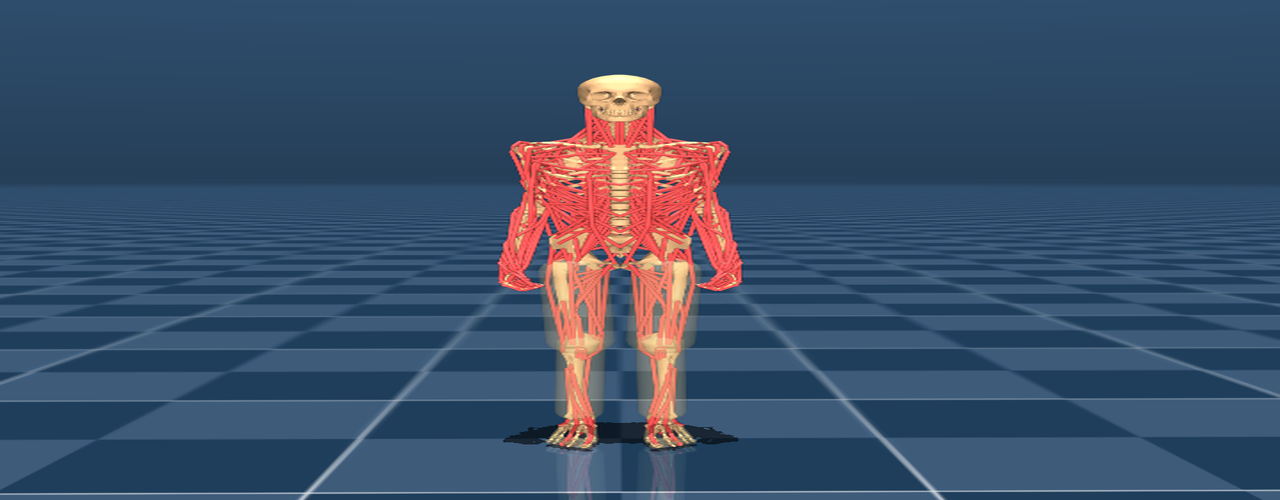

In [4]:

mujoco.mj_forward(mj_model, mj_data)

renderer.update_scene(mj_data, camera="record_camera")
image = renderer.render()

image = np.asarray(
    Image.fromarray(image).resize(
        (width, height),
        resample=Image.Resampling.LANCZOS,
    )
)

media.show_image(image)
media.write_image(
    str(media_dir / "ms_human_700_initial.png"),
    image,
)

## Zero-control rollout

The model is stepped with zero actuator controls and rendered at 30 frames per second.

In [5]:
duration = 3.0
framerate = 30
frames = []
mujoco.mj_resetData(mj_model, mj_data)
mujoco.mj_forward(mj_model, mj_data)
next_frame_time = 0.0

while mj_data.time < duration:
    mujoco.mj_step(mj_model, mj_data)
    if mj_data.time >= next_frame_time:
        renderer.update_scene(mj_data, camera="record_camera")
        frames.append(renderer.render())
        next_frame_time += 1 / framerate

media.show_video(np.asarray(frames), fps=framerate)

This browser does not support the video tag.
